# Fase 5 · Validación con varios cortes temporales y alertas de brote

El notebook 09 respondió la hipótesis **H2** (¿el clima mejora el pronóstico?) con un solo corte, y la respuesta se contradijo: **sí** en validación 2022–2023 y **no** en la prueba 2024. Este notebook la revisa con más años y agrega lo que más le importa a la vigilancia: **¿el modelo avisa a tiempo de los brotes?**

**1. Validación con origen móvil** (*rolling origin*). Para cada año evaluado *Y* de 2016 a 2024:

| Paso | Años |
|---|---|
| Seleccionar variables climáticas y ajustar hiperparámetros | entrenamiento hasta *Y* − 2, validación en *Y* − 1 |
| Reentrenar el modelo final | hasta *Y* − 1 |
| Evaluar | año *Y* (nunca visto) |

Así se obtienen **9 años de prueba** en lugar de uno. Se comparan la persistencia, la regresión con casos rezagados, el XGBoost sin clima y el XGBoost con clima, todos con el objetivo "delta" (el que eligió la validación del notebook 09 en el 92 % de los casos).

**2. Alertas de brote.** Una semana es de **brote** si los casos superan el **canal endémico**: el percentil 75 (Q3) de la misma semana en los 7 años previos no epidémicos (sin 2017, 2023 ni 2024) y además hay al menos 5 casos. Es la definición "B2" del proyecto anterior del equipo; el umbral solo usa años anteriores, así que se conoce de antemano.

Un modelo **da la alerta** para la semana *T* si su pronóstico (hecho en *T − h*) supera ese umbral. Métricas:
- **Precisión:** de las alertas, cuántas fueron brotes reales.
- **Recall:** de los brotes, cuántos tuvieron alerta.
- **F1:** combina precisión y recall.
- **Falsas alarmas por departamento y año.**
- **% de brotes nuevos anticipados:** semanas en que empieza un brote **nuevo** (ninguna semana de brote en las 4 anteriores) y que el modelo marcó con *h* semanas de anticipación. Es lo más útil para actuar antes del pico.

⏱️ Entrenar todo tarda unos **30 minutos** (9 años × 17 departamentos × 4 horizontes × 2 variantes × 6 configuraciones). Por defecto (`REENTRENAR = False`) se reutilizan las predicciones guardadas en `data/processed/predicciones_validacion_temporal.parquet`.

## Configuración

In [1]:
# Rutas: el notebook funciona desde la raiz del proyecto o desde notebooks/
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))  # para importar scripts/comun.py y scripts/modelado.py

In [2]:
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

from comun import HORIZONTES, REGIONES
from modelado import (MAX_ARBOLES, N_REZAGOS, REJILLA, a_casos, candidatas, departamentos_modelables,
                      marcar_brotes, metricas, modelo_xgb, objetivo_de, preparar_panel, seleccionar,
                      umbral_brote)

PROC = ROOT / "data" / "processed"
INTERIM = ROOT / "data" / "interim"
OUT = ROOT / "outputs"

ANIOS_EVALUADOS = list(range(2016, 2025))   # cada uno es un corte: se entrena con los anos anteriores
REJILLA_DELTA = [c for c in REJILLA if c["objetivo"] == "delta"]
# True: vuelve a entrenar todo (~30 min). False: usa las predicciones guardadas si existen.
REENTRENAR = False
ARCHIVO_PREDICCIONES = PROC / "predicciones_validacion_temporal.parquet"

PERSISTENCIA, REGRESION = "Persistencia", "Regresion con rezagos"
SIN_CLIMA, CON_CLIMA = "XGBoost sin clima", "XGBoost con clima"
MODELOS = [PERSISTENCIA, REGRESION, SIN_CLIMA, CON_CLIMA]

## Datos

In [3]:
panel = preparar_panel(pd.read_parquet(PROC / "panel_depto_semana.parquet"))
deptos, _ = departamentos_modelables(panel)
print(f"Departamentos ({len(deptos)}): {', '.join(deptos)}")
print(f"Anos evaluados: {ANIOS_EVALUADOS[0]}-{ANIOS_EVALUADOS[-1]}; configuraciones por modelo: {len(REJILLA_DELTA)}")

Departamentos (17): AMAZONAS, ANCASH, AYACUCHO, CAJAMARCA, CUSCO, HUANUCO, ICA, JUNIN, LA LIBERTAD, LAMBAYEQUE, LORETO, MADRE DE DIOS, PASCO, PIURA, SAN MARTIN, TUMBES, UCAYALI
Anos evaluados: 2016-2024; configuraciones por modelo: 6


## Modelado con origen móvil

Para cada año evaluado, departamento y horizonte: la selección de variables climáticas y la elección de hiperparámetros solo usan años anteriores al evaluado.

In [4]:
def ajustar_xgb(cols, tr, va, final_df, ev, h):
    """Elige la configuracion por MAE en va, reentrena con final_df y predice ev."""
    mejor = None
    for config in REJILLA_DELTA:
        m = modelo_xgb(config, MAX_ARBOLES, parada=True)
        m.fit(tr[cols], objetivo_de(config, tr, h), eval_set=[(va[cols], objetivo_de(config, va, h))],
              verbose=False)
        mae = mean_absolute_error(va["casos"], a_casos(config, m.predict(va[cols]), va, h))
        if mejor is None or mae < mejor[0]:
            mejor = (mae, config, m.best_iteration + 1)
    _, config, n_arboles = mejor
    final = modelo_xgb(config, n_arboles, parada=False)
    final.fit(final_df[cols], objetivo_de(config, final_df, h), verbose=False)
    return a_casos(config, final.predict(ev[cols]), ev, h)


def entrenar_todo() -> pd.DataFrame:
    predicciones = []
    inicio = time.time()
    for anio in ANIOS_EVALUADOS:
        for depto in deptos:
            d = panel[panel["departamento"] == depto]
            for h in HORIZONTES:
                base = [f"casos_l{k}" for k in range(h, h + N_REZAGOS)] + ["sem_sin", "sem_cos"]
                tr = d[d["ano"] <= anio - 2].dropna(subset=base)          # ajustar y seleccionar
                va = d[d["ano"] == anio - 1]                               # elegir hiperparametros
                final_df = d[d["ano"] <= anio - 1].dropna(subset=base)     # modelo final
                ev = d[d["ano"] == anio]                                   # evaluar
                clima, _ = seleccionar(tr, candidatas(h, h + N_REZAGOS - 1))
                con_clima = base + clima
                final_df_clima = final_df.dropna(subset=con_clima)
                tr_clima = tr.dropna(subset=con_clima)

                rezagos = [f"casos_l{k}" for k in range(h, h + N_REZAGOS)]
                regresion = LinearRegression().fit(final_df[rezagos], final_df["log_casos"])
                preds = {
                    PERSISTENCIA: np.expm1(ev[f"casos_l{h}"].to_numpy()),
                    REGRESION: np.clip(np.expm1(regresion.predict(ev[rezagos])), 0, None),
                    SIN_CLIMA: ajustar_xgb(base, tr, va, final_df, ev, h),
                    CON_CLIMA: ajustar_xgb(con_clima, tr_clima, va, final_df_clima, ev, h),
                }
                for modelo, p in preds.items():
                    predicciones.append(pd.DataFrame({
                        "anio_evaluado": anio, "departamento": depto, "horizonte": h, "modelo": modelo,
                        "ano": ev["ano"].to_numpy(), "semana": ev["semana"].to_numpy(),
                        "fecha": ev["fecha"].to_numpy(), "casos": ev["casos"].to_numpy(), "prediccion": p}))
        print(f"  {anio} listo ({time.time() - inicio:,.0f} s)")
    return pd.concat(predicciones, ignore_index=True)


if REENTRENAR or not ARCHIVO_PREDICCIONES.exists():
    pred = entrenar_todo()
    pred.to_parquet(ARCHIVO_PREDICCIONES, index=False)
else:
    pred = pd.read_parquet(ARCHIVO_PREDICCIONES)
    print(f"Usando las predicciones guardadas en {ARCHIVO_PREDICCIONES.name} (REENTRENAR = False)")
print(f"{len(pred):,} predicciones semanales")

Usando las predicciones guardadas en predicciones_validacion_temporal.parquet (REENTRENAR = False)
127,568 predicciones semanales


## H2 con 9 años de prueba: ¿el clima mejora el pronóstico?

Para cada año y horizonte se cuenta en cuántos de los 17 departamentos el XGBoost **con clima** tiene menor error (MAE) que el XGBoost **sin clima**. Si el clima no aportara nada, se esperaría alrededor de la mitad (8 a 9 de 17).

In [5]:
filas = []
for (anio, depto, h, modelo), df in pred.groupby(["anio_evaluado", "departamento", "horizonte", "modelo"]):
    filas.append({"anio_evaluado": anio, "departamento": depto, "horizonte": h, "modelo": modelo,
                  **metricas(df["casos"], df["prediccion"])})
met = pd.DataFrame(filas)
met.to_csv(OUT / "fase5_validacion_temporal_metricas.csv", index=False, float_format="%.4f")

mae = met.pivot_table(index=["anio_evaluado", "departamento", "horizonte"], columns="modelo", values="mae")
gana = (mae[CON_CLIMA] < mae[SIN_CLIMA]).groupby(level=["anio_evaluado", "horizonte"]).sum().unstack()
print("Departamentos (de 17) donde el clima reduce el error, por ano evaluado y horizonte:")
print(gana.to_string())

# Error total de los 9 anos por departamento: una comparacion mas estable que ano por ano
mae_total = (pred.assign(error=(pred["casos"] - pred["prediccion"]).abs())
             .groupby(["departamento", "horizonte", "modelo"])["error"].mean().unstack())
mejora = (mae_total[SIN_CLIMA] - mae_total[CON_CLIMA]) / mae_total[SIN_CLIMA] * 100
resumen_h2 = pd.DataFrame({
    "deptos_donde_clima_mejora": (mejora > 0).groupby(level="horizonte").sum(),
    "mejora_mediana_%": mejora.groupby(level="horizonte").median().round(1),
    "anos_con_mayoria_a_favor": (gana > len(deptos) / 2).sum(),
})
print("\nSobre el error total 2016-2024:")
print(resumen_h2.to_string())

print("\nMAE total 2016-2024 de las regiones principales (casos por semana):")
print(mae_total.loc[REGIONES][MODELOS].round(1).to_string())

Departamentos (de 17) donde el clima reduce el error, por ano evaluado y horizonte:
horizonte       1   2   3   4
anio_evaluado                
2016            8   9   9  10
2017            7   5   4   7
2018           10   9   9   8
2019            8   6   6   9
2020            6  10   9   8
2021            5   5   8   7
2022            7  11   5   7
2023            9   7  11  12
2024            6   8   7   8

Sobre el error total 2016-2024:
           deptos_donde_clima_mejora  mejora_mediana_%  anos_con_mayoria_a_favor
horizonte                                                                       
1                                  8              -1.3                         2
2                                 10               0.6                         4
3                                  8              -0.5                         4
4                                 11               1.6                         3

MAE total 2016-2024 de las regiones principales (casos por semana)

## Alertas de brote

In [6]:
casos_depto = pd.read_parquet(INTERIM / "casos_depto_semana.parquet")  # historia desde 2000
umbrales = umbral_brote(casos_depto)

# Brotes reales y brotes NUEVOS sobre la serie completa: brote en T sin ninguna semana de
# brote en las 4 anteriores. Con solo "la semana anterior no era de brote", el 60 % de los
# inicios eran reentradas al umbral de episodios en curso (331 frente a 134 brotes nuevos).
SEMANAS_SIN_BROTE = 4
serie = marcar_brotes(panel[["departamento", "ano", "semana", "casos"]], umbrales)
serie = serie.sort_values(["departamento", "ano", "semana"])
g_brote = serie.groupby("departamento")["brote"]
previos = sum(g_brote.shift(k, fill_value=False).astype(int) for k in range(1, SEMANAS_SIN_BROTE + 1))
serie["inicio_brote"] = serie["brote"] & (previos == 0)

alertas = pred.merge(serie[["departamento", "ano", "semana", "umbral", "brote", "inicio_brote"]],
                     on=["departamento", "ano", "semana"], how="left")
assert alertas["umbral"].notna().all()
alertas["alerta"] = (alertas["prediccion"] > alertas["umbral"]) & (alertas["prediccion"] >= 5)
print(f"Semanas de brote evaluadas: {alertas.drop_duplicates(['departamento', 'ano', 'semana'])['brote'].mean():.1%}")


def metricas_alerta(df):
    vp = (df["alerta"] & df["brote"]).sum()
    fp = (df["alerta"] & ~df["brote"]).sum()
    fn = (~df["alerta"] & df["brote"]).sum()
    inicios = df["inicio_brote"]
    return pd.Series({
        "precision": vp / max(vp + fp, 1), "recall": vp / max(vp + fn, 1),
        "f1": 2 * vp / max(2 * vp + fp + fn, 1),
        "falsas_alarmas_por_depto_anio": fp / df.groupby(["departamento", "ano"]).ngroups,
        "inicios_anticipados": (df["alerta"] & inicios).sum() / max(inicios.sum(), 1),
        "n_inicios": int(inicios.sum()),
    })


tabla_alertas = alertas.groupby(["horizonte", "modelo"]).apply(metricas_alerta)
tabla_alertas = tabla_alertas.reindex([(h, m) for h in HORIZONTES for m in MODELOS])
tabla_alertas.to_csv(OUT / "fase5_alertas.csv", float_format="%.4f")
print("\nAlertas, todos los departamentos, 2016-2024:")
print(tabla_alertas.round(3).to_string())

por_region = alertas[alertas["departamento"].isin(REGIONES) & (alertas["horizonte"] == 2)]
print("\nAlertas a 2 semanas en las regiones principales:")
# pandas 3 no pasa las columnas de agrupacion a apply: se agrupa por una copia
print(por_region.assign(region=por_region["departamento"]).groupby(["region", "modelo"]).apply(metricas_alerta)
      .reindex([(d, m) for d in REGIONES for m in MODELOS]).round(3).to_string())

Semanas de brote evaluadas: 44.8%



Alertas, todos los departamentos, 2016-2024:
                                 precision  recall     f1  falsas_alarmas_por_depto_anio  inicios_anticipados  n_inicios
horizonte modelo                                                                                                        
1         Persistencia               0.914   0.920  0.917                          2.020                0.276      134.0
          Regresion con rezagos      0.936   0.895  0.915                          1.425                0.201      134.0
          XGBoost sin clima          0.933   0.904  0.918                          1.516                0.224      134.0
          XGBoost con clima          0.933   0.899  0.916                          1.503                0.246      134.0
2         Persistencia               0.895   0.894  0.894                          2.444                0.209      134.0
          Regresion con rezagos      0.917   0.859  0.887                          1.817                0.1

## Gráficos

In [7]:
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
TINTA, TINTA_2, REJ = "#0b0b0b", "#52514e", "#e1e0d9"
COLORES = {PERSISTENCIA: AQUA, REGRESION: AMARILLO, SIN_CLIMA: MAGENTA, CON_CLIMA: AZUL}
COLOR_H = {1: "#cde2fb", 2: "#86b6ef", 3: "#256abf", 4: "#0d366b"}


def estilo(ax):
    ax.grid(color=REJ, lw=0.6)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)

### H2 año por año

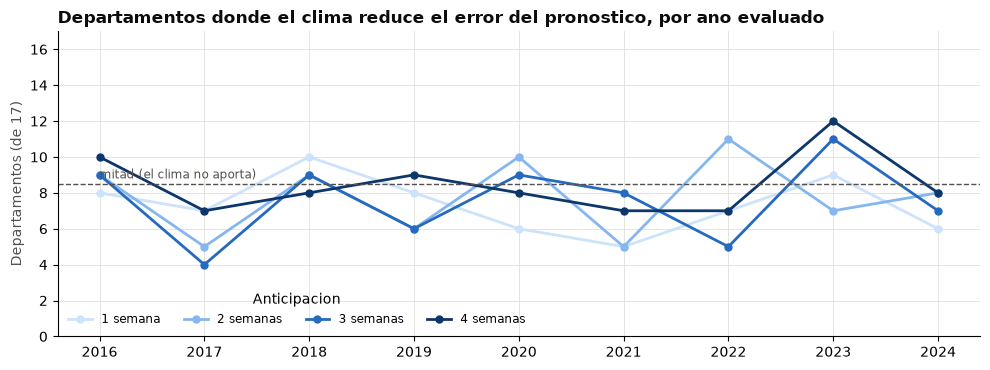

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for h in HORIZONTES:
    ax.plot(gana.index, gana[h], marker="o", ms=5, lw=2, color=COLOR_H[h], label=f"{h} semana{'s' if h > 1 else ''}")
ax.axhline(len(deptos) / 2, color=TINTA_2, lw=1, ls="--")
ax.text(gana.index[0], len(deptos) / 2 + 0.3, "mitad (el clima no aporta)", fontsize=8.5, color=TINTA_2)
ax.set_ylim(0, len(deptos))
ax.set_xticks(gana.index)
ax.set_ylabel(f"Departamentos (de {len(deptos)})", color=TINTA_2)
ax.set_title("Departamentos donde el clima reduce el error del pronostico, por ano evaluado",
             loc="left", fontsize=12, fontweight="bold", color=TINTA)
ax.legend(title="Anticipacion", ncol=4, frameon=False, fontsize=8.5, loc="lower left")
estilo(ax)
fig.tight_layout()
fig.savefig(OUT / "fase5_h2_por_anio.png", dpi=120)
plt.show()

### Alertas por modelo

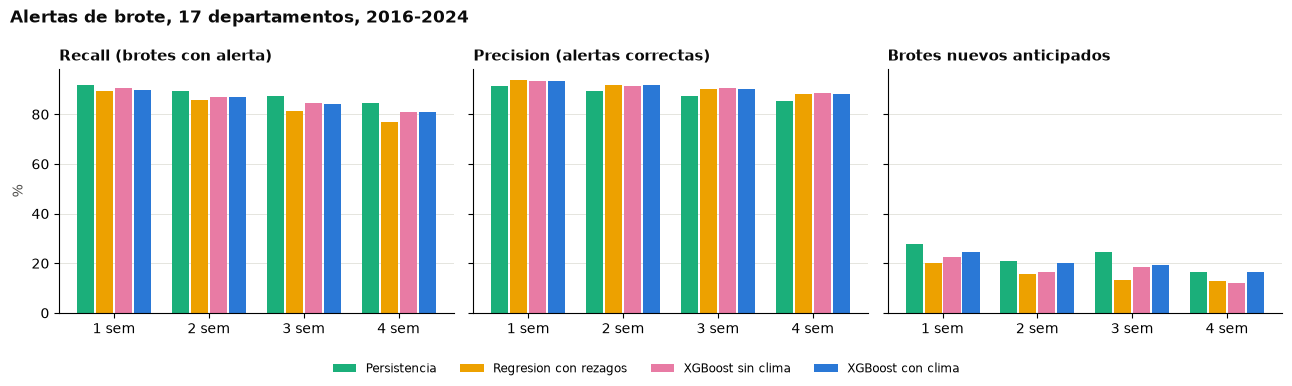

In [9]:
indicadores = [("recall", "Recall (brotes con alerta)"), ("precision", "Precision (alertas correctas)"),
               ("inicios_anticipados", "Brotes nuevos anticipados")]
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
ancho = 0.2
for ax, (col, titulo) in zip(ejes, indicadores):
    for i, modelo in enumerate(MODELOS):
        valores = [tabla_alertas.loc[(h, modelo), col] * 100 for h in HORIZONTES]
        ax.bar(np.arange(len(HORIZONTES)) + (i - 1.5) * ancho, valores, width=ancho - 0.02,
               color=COLORES[modelo], label=modelo)
    ax.set_xticks(range(len(HORIZONTES)), [f"{h} sem" for h in HORIZONTES])
    ax.set_title(titulo, loc="left", fontsize=11, fontweight="bold", color=TINTA)
    estilo(ax)
    ax.grid(axis="x", visible=False)
ejes[0].set_ylabel("%", color=TINTA_2)
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, fontsize=8.5)
fig.suptitle("Alertas de brote, 17 departamentos, 2016-2024", x=0.01, ha="left", fontsize=12,
             fontweight="bold", color=TINTA)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(OUT / "fase5_alertas.png", dpi=120)
plt.show()

### Ejemplo: alertas a 2 semanas en Piura

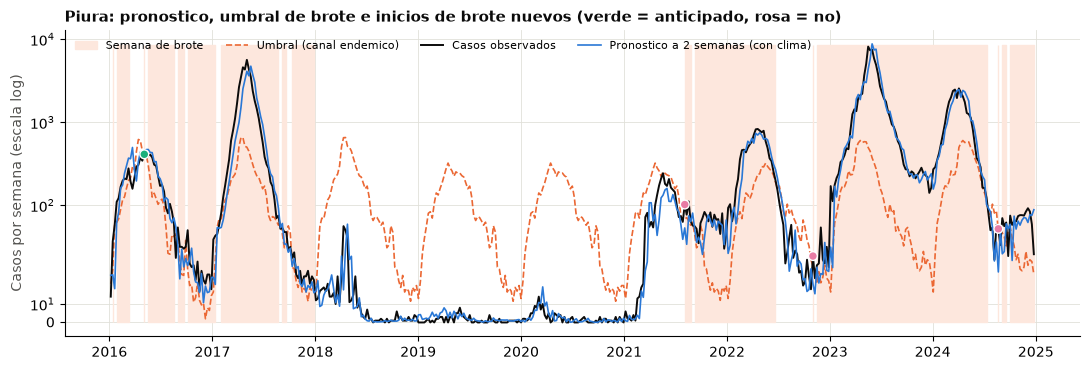

In [10]:
H_EJEMPLO, DEPTO_EJEMPLO = 2, "PIURA"
ej = alertas[(alertas["departamento"] == DEPTO_EJEMPLO) & (alertas["horizonte"] == H_EJEMPLO)
             & (alertas["modelo"] == CON_CLIMA)].sort_values("fecha")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(ej["fecha"], 0, ej["casos"].max() * 1.05, where=ej["brote"], step="mid", color="#fde7dd",
                label="Semana de brote")
ax.plot(ej["fecha"], ej["umbral"], color=NARANJA, lw=1.2, ls="--", label="Umbral (canal endemico)")
ax.plot(ej["fecha"], ej["casos"], color=TINTA, lw=1.4, label="Casos observados")
ax.plot(ej["fecha"], ej["prediccion"], color=AZUL, lw=1.2, label=f"Pronostico a {H_EJEMPLO} semanas (con clima)")
inicios = ej[ej["inicio_brote"]]
ax.scatter(inicios["fecha"], inicios["casos"], s=40, zorder=3,
           color=[AQUA if a else MAGENTA for a in inicios["alerta"]], edgecolor="white")
ax.set_yscale("symlog", linthresh=50)
ax.set_ylabel("Casos por semana (escala log)", color=TINTA_2)
ax.set_title(f"{DEPTO_EJEMPLO.title()}: pronostico, umbral de brote e inicios de brote "
             f"nuevos (verde = anticipado, rosa = no)", loc="left", fontsize=11, fontweight="bold", color=TINTA)
ax.legend(loc="upper left", ncol=4, frameon=False, fontsize=8)
estilo(ax)
fig.tight_layout()
fig.savefig(OUT / "fase5_alertas_piura.png", dpi=120)
plt.show()

## Resultados y conclusiones

### H2 con 9 años de prueba: el clima no mejora el pronóstico de forma consistente

| Anticipación | Departamentos donde el clima reduce el error total 2016–2024 | Mejora mediana del error | Años con mayoría a favor del clima |
|---|---|---|---|
| 1 semana | 8 de 17 | −1,3 % | 2 de 9 |
| 2 semanas | 10 de 17 | +0,6 % | 4 de 9 |
| 3 semanas | 8 de 17 | −0,5 % | 4 de 9 |
| 4 semanas | 11 de 17 | +1,6 % | 3 de 9 |

- Año a año, el clima gana en **alrededor de la mitad** de los departamentos, que es lo que se esperaría si no aportara nada.
- **2022 y 2023 fueron años favorables al clima** (hasta 11–12 de 17). Eso explica por qué la validación del notebook 09, que usaba justo esos años, parecía confirmar H2.
- **Conclusión:** con estos datos de clima (promedio de celdas de unos 55 km por departamento) y este modelo, **el clima no agrega una mejora robusta** sobre los casos pasados y la estacionalidad. Es un resultado negativo honesto y útil.

### XGBoost sí mejora a las líneas base

Error total 2016–2024 (MAE, casos por semana) a 2 / 4 semanas:

| Región | Persistencia | Regresión | XGBoost sin clima | XGBoost con clima |
|---|---|---|---|---|
| Piura | 146 / 265 | 132 / 202 | **108** / 182 | 113 / **180** |
| Loreto | 29,7 / 43,3 | 29,4 / 42,3 | 28,8 / 39,9 | **28,0** / **39,7** |
| San Martín | 16,9 / 25,0 | 21,2 / 29,6 | **16,4** / 24,0 | 16,7 / **23,3** |

En Piura, el XGBoost reduce el error de la persistencia en 26–32 %. La mejora viene del modelo, no del clima.

### Alertas de brote (17 departamentos, 2016–2024)

- **Precisión y recall altos para todos los modelos** (0,85–0,94): los brotes duran varias semanas, así que avisar de un brote que **sigue** es fácil. Ojo: el 45 % de las semanas evaluadas son de brote, porque a nivel de departamento el canal endémico se supera con frecuencia, sobre todo en los años de expansión del dengue.
- **Lo difícil es anticipar un brote nuevo** (sin brote en las 4 semanas previas; 134 en total). Todos los modelos anticipan solo el **12–28 %**:

| Anticipación | Persistencia | Regresión | XGBoost sin clima | XGBoost con clima |
|---|---|---|---|---|
| 2 semanas | 20,9 % | 15,7 % | 16,4 % | 20,1 % |
| 4 semanas | 16,4 % | 12,7 % | 11,9 % | 16,4 % |

- **Aquí el clima sí ayuda un poco:** el XGBoost con clima anticipa más brotes nuevos que el sin clima a 2, 3 y 4 semanas (20,1 % frente a 16,4 % a 2 semanas). Pero no supera a la persistencia, y con solo 134 brotes nuevos la diferencia puede ser azar. Es una pista para la siguiente etapa, no una conclusión.
- **Las regiones modelo tienen pocos brotes nuevos** (Piura 4, Loreto 11, San Martín 7), así que sus porcentajes no son confiables por separado.

### Conclusiones generales

1. **Con un solo corte se puede llegar a la conclusión equivocada.** La validación 2022–2023 decía que el clima ayudaba; con 9 años no se sostiene.
2. **El XGBoost aprendiendo el cambio es el mejor pronosticador de casos,** sobre todo en Piura, pero su ventaja no viene del clima.
3. **Anticipar el inicio de un brote sigue siendo el problema principal:** ningún modelo pasa del 28 %. Es el argumento para buscar mejores predictores: clima más fino (estaciones del SENAMHI, ERA5-Land), datos de vectores, movilidad o reportes más rápidos.

**Limitaciones:**
- En cada corte solo se probó el objetivo "delta" con 6 configuraciones.
- El umbral de brote a nivel de departamento es permisivo.
- Las cifras de las regiones modelo por separado se basan en pocos brotes nuevos.
